# Align

## 方法总览
RNA 与 MSI 的空间对齐，本质上是先在两种模态的空间图中确定若干组对应的 landmark。这里的 landmark 不是生物学意义上的 marker，而是几何上的对应位置，即 RNA 图中的某个位置与 MSI 图中的某个位置代表真实组织中的同一区域。只要组织轮廓、边界、尖角、凹陷等结构足够明显，这些对应点并不一定必须由医学专家确定，具备图像处理经验的人也可以进行标注；但在组织结构较复杂的情况下，领域专家参与会更可靠。NicheTrans 的 B1 样本中给出了 9 对 RNA–MSI 对应坐标。

这些 landmark 的作用并不是只把这几个点本身对齐，而是利用这些已知对应关系计算一个从 MSI 坐标系到 RNA 坐标系的整体几何变换。代码通过 `cv2.findHomography()` 根据两组 landmark 估计一个 3×3 的 Homography 变换矩阵，该矩阵描述 MSI 整体需要进行的平移、旋转、缩放、倾斜和透视变换。理论上 4 对不共线的对应点即可估计 Homography，作者使用更多 landmark 可以提高变换估计的稳定性，并结合 LMEDS 降低个别对应点存在误差时的影响。

获得 Homography 矩阵后，再通过 `cv2.warpPerspective()` 将整个 MSI 空间映射到 RNA 的坐标系中。因此，不只是 landmark 发生变化，而是 MSI 中所有空间位置以及每一个 metabolite 通道都按照同一个空间变换规则重新定位。完成对齐后，就可以根据每个 RNA spot 的空间坐标，在对齐后的 MSI 数据中提取相同位置的 metabolite 信号，最终形成与 RNA spot 一一对应的 `Spot × Metabolite` 数据，从而建立“同一个空间位置的 RNA 表达与代谢物表达”之间的对应关系。

## 展示图讲解
MSI aligned to RNA：原来的 MSI 图经过 Homography + warpPerspective 之后，已经被“扭”到了 RNA 的坐标系里。现在它的外轮廓、方向、大小，应该和 RNA 空间图尽量一致。

RMA + MSI aligned：把 RNA 空间图和已经配准到 RNA 坐标系的 MSI 图半透明叠放，用来直观看两种模态的组织轮廓和空间位置是否基本重合。

## 坐标选取原则
选 landmark 坐标的原理就是：**在 RNA 图和 MSI 图里，找那些“能够确定是同一个真实组织位置”的特征点。**

通常会优先选这些位置：组织外轮廓的尖角、明显凹陷、边界转折点、形状独特的突出部位，或者内部非常明显的结构节点。因为这些位置在两种模态里相对容易一一对应。

选点时有几个原则：点要**分布在整个组织范围内**，不能都挤在一个小区域；尽量选**不共线**的点；每一对点都要有明确对应关系。这样算出来的 Homography 才能稳定描述整张图的旋转、缩放、平移和透视变化。

所以本质上不是“挑信号最强的点”，而是：

> **挑几组几何结构上最容易确认对应关系的位置，用这些点来估计两个空间坐标系之间的整体变换。**

RNA H5: True
RNA positions: True
MSI: True
save_dir: E:\PythonProject\demo-python\processed_data\SMA\V11L12-109_B1

原始 H5 matrix shape:
[32285  3120]
data length:
6346361
indices length:
6346361
indptr length:
3121

原始 RNA matrix:
(32285, 3120)

转置后 RNA matrix:
(3120, 32285)

Spot 数量:
3120
Gene 数量:
32285

RNA positions shape:
(4992, 6)

RNA positions 前5行:
              barcode  in_tissue  array_row  array_col  pixel_row  pixel_col
0  ACGCCTGACACGCGCT-1          0          0          0       5345       5233
1  TACCGATCCAACACTT-1          0          1          1       5850       5521
2  ATTAAAGCGGACGAGC-1          0          0          2       5346       5813
3  GATAAGGGACGATTAG-1          0          1          3       5852       6101
4  GTGCAAATCACCAATA-1          0          0          4       5348       6392

对齐后 RNA expression shape:
(3120, 32285)

对齐后 position 数量:
3120

RNA spatial array shape:
(74, 128)

MSI shape:
(4914, 1540)

MSI 前5列:
['x', 'y', '156.26059', '156.26195', '156.483

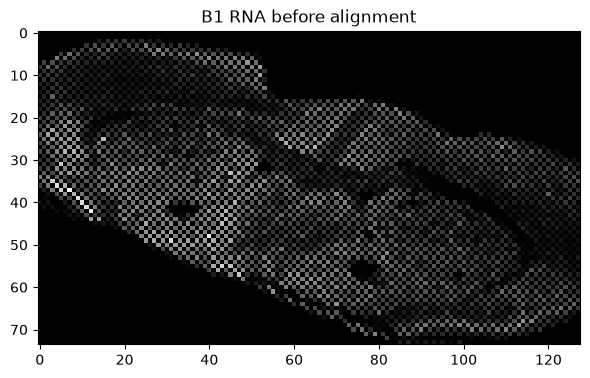

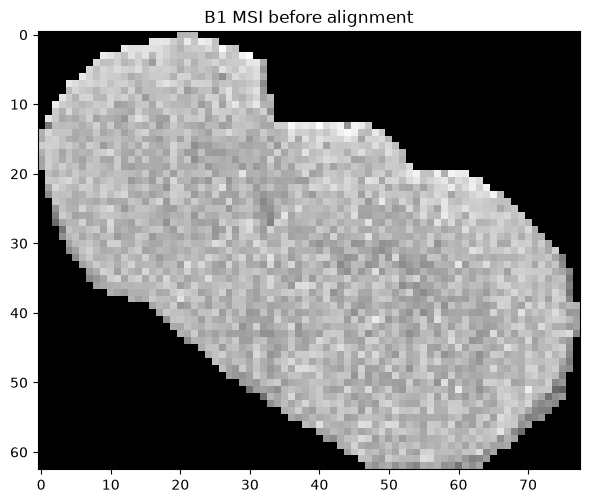

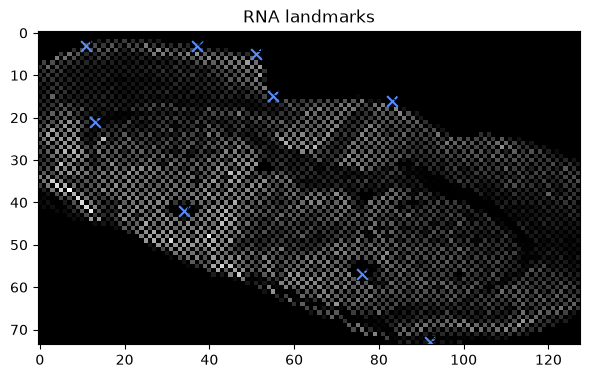

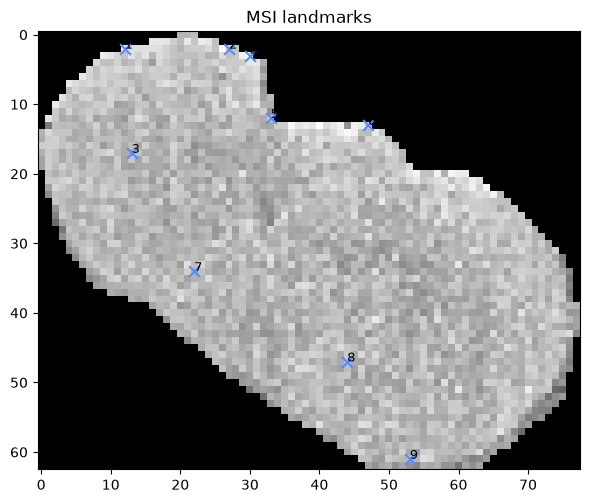


Homography matrix:
[[ 2.28411128e+00 -4.98446788e-03 -1.54426062e+01]
 [ 4.70040422e-02  1.32570529e+00 -9.02924170e-01]
 [ 2.13608533e-03  4.32865100e-04  1.00000000e+00]]

Landmark mask:
[1 0 1 1 1 1 1 1 1]

Aligned MSI shape:
(74, 128)


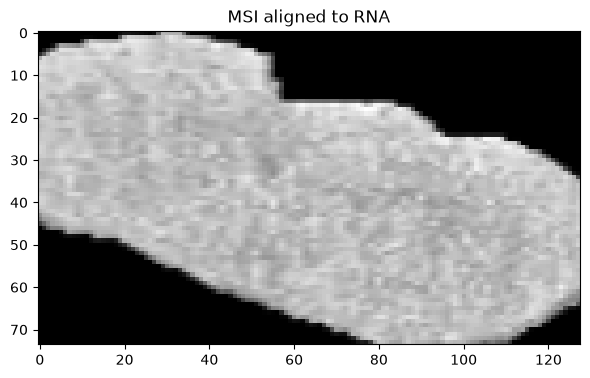

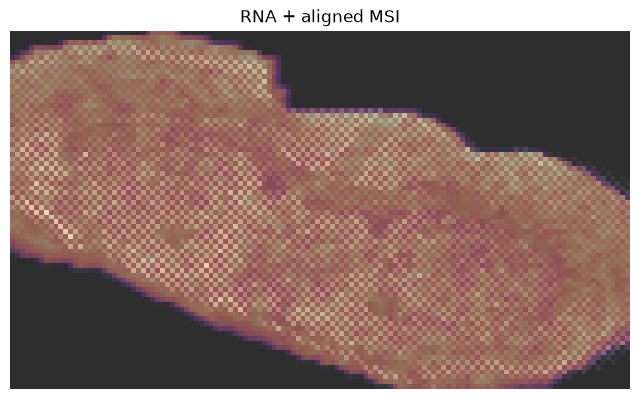


最终 aligned MSI shape:
(74, 128, 1538)

保存完成:
E:\PythonProject\demo-python\processed_data\SMA\V11L12-109_B1\B1_aligned_MSI.npy
E:\PythonProject\demo-python\processed_data\SMA\V11L12-109_B1\B1_homography_matrix.npy


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import h5py

from scipy.sparse import csc_matrix


# =========================================================
# 1. 路径
# =========================================================

PATH_SMA = Path(r"E:\Data\SMA")

mouse_name = "V11L12-109_B1"

path_rna_h5 = (
    PATH_SMA
    / "GSM7392315_V11L12-109_B1_RNA_filtered_feature_bc_matrix.h5"
)

path_rna_positions = (
    PATH_SMA
    / "GSM7392315_V11L12-109_B1_RNA_tissue_positions_list.csv.gz"
)

path_meta = (
    PATH_SMA
    / "V11L12-109_B1.Visium.FMP.220826_smamsi.csv"
)

save_dir = (
    Path.cwd()
    / "processed_data"
    / "SMA"
    / mouse_name
)

save_dir.mkdir(
    parents=True,
    exist_ok=True
)

print("RNA H5:", path_rna_h5.exists())
print("RNA positions:", path_rna_positions.exists())
print("MSI:", path_meta.exists())
print("save_dir:", save_dir)


# =========================================================
# 2. NicheTrans 作者提供的 B1 landmark
# =========================================================

points_rna = [
    [11, 3],
    [37, 3],
    [13, 21],
    [51, 5],
    [55, 15],
    [83, 16],
    [34, 42],
    [76, 57],
    [92, 73]
]

points_meta = [
    [12, 2],
    [27, 2],
    [13, 17],
    [30, 3],
    [33, 12],
    [47, 13],
    [22, 34],
    [44, 47],
    [53, 61]
]


# =========================================================
# 3. 读取 RNA expression matrix
#    10x H5 内部使用 CSC sparse matrix
# =========================================================

with h5py.File(path_rna_h5, "r") as f:

    matrix = f["matrix"]

    data = matrix["data"][:]
    indices = matrix["indices"][:]
    indptr = matrix["indptr"][:]
    shape = matrix["shape"][:]

    barcodes = (
        matrix["barcodes"][:]
        .astype(str)
    )

    gene_names = (
        matrix["features"]["name"][:]
        .astype(str)
    )


print("\n原始 H5 matrix shape:")
print(shape)

print("data length:")
print(len(data))

print("indices length:")
print(len(indices))

print("indptr length:")
print(len(indptr))


# 10x H5：
# rows = genes
# columns = spots
#
# 内部存储是 CSC
rna_matrix = csc_matrix(
    (data, indices, indptr),
    shape=tuple(shape)
)

print("\n原始 RNA matrix:")
print(rna_matrix.shape)


# 转成：
# spot × gene
rna_matrix = (
    rna_matrix
    .T
    .tocsr()
)

print("\n转置后 RNA matrix:")
print(rna_matrix.shape)

print("\nSpot 数量:")
print(len(barcodes))

print("Gene 数量:")
print(len(gene_names))


# =========================================================
# 4. 读取 Visium spot 坐标
# =========================================================

positions = pd.read_csv(
    path_rna_positions,
    compression="gzip",
    header=None
)

positions.columns = [
    "barcode",
    "in_tissue",
    "array_row",
    "array_col",
    "pixel_row",
    "pixel_col"
]

positions["barcode"] = (
    positions["barcode"]
    .astype(str)
)

print("\nRNA positions shape:")
print(positions.shape)

print("\nRNA positions 前5行:")
print(positions.head())


# =========================================================
# 5. RNA expression 与 spot 坐标按 barcode 对齐
# =========================================================

barcode_to_index = {
    barcode: i
    for i, barcode in enumerate(barcodes)
}


valid_positions = positions[
    positions["barcode"].isin(
        barcode_to_index
    )
].copy()


rna_indices = [
    barcode_to_index[barcode]
    for barcode
    in valid_positions["barcode"]
]


rna_aligned = (
    rna_matrix[
        rna_indices,
        :
    ]
)


print("\n对齐后 RNA expression shape:")
print(rna_aligned.shape)

print("\n对齐后 position 数量:")
print(len(valid_positions))


# =========================================================
# 6. 构造 RNA 空间图
#
# 一个 spot 的所有 gene count 求和
# 这里只是为了可视化 RNA 的空间形状
# =========================================================

max_row = int(
    valid_positions["array_row"].max()
)

max_col = int(
    valid_positions["array_col"].max()
)


vis_rna_array = np.zeros(
    (
        max_row + 1,
        max_col + 1
    ),
    dtype=np.float32
)


rna_total = np.asarray(
    rna_aligned.sum(axis=1)
).ravel()


valid_positions_reset = (
    valid_positions
    .reset_index(drop=True)
)


for i, row in valid_positions_reset.iterrows():

    array_row = int(
        row["array_row"]
    )

    array_col = int(
        row["array_col"]
    )

    vis_rna_array[
        array_row,
        array_col
    ] = rna_total[i]


print("\nRNA spatial array shape:")
print(vis_rna_array.shape)


# =========================================================
# 7. 读取 MSI
# =========================================================

msi_file = pd.read_csv(
    path_meta
)

print("\nMSI shape:")
print(msi_file.shape)

print("\nMSI 前5列:")
print(
    msi_file.columns[:5].tolist()
)

print("\nMSI 前5行前5列:")
print(
    msi_file.iloc[:5, :5]
)


# 默认：
# 前两列 = x, y
# 后面的列 = metabolite intensity

msi_data_array = (
    msi_file
    .iloc[:, 2:]
    .to_numpy(
        dtype=np.float32
    )
)

print("\nMetabolite matrix shape:")
print(msi_data_array.shape)


# =========================================================
# 8. 构造 MSI 空间图
#
# 作者代码对 MSI y 坐标做翻转：
# new_y = max(y) - y
# =========================================================

msi_x = (
    msi_file.iloc[:, 0]
    .to_numpy()
    .astype(int)
)

msi_y = (
    msi_file.iloc[:, 1]
    .to_numpy()
    .astype(int)
)


msi_row = msi_x

msi_col = (
    msi_y.max()
    - msi_y
)


max_meta_row = int(
    msi_row.max()
)

max_meta_col = int(
    msi_col.max()
)


vis_meta_array = np.zeros(
    (
        max_meta_row + 1,
        max_meta_col + 1
    ),
    dtype=np.float32
)


# 保存所有 metabolite channel
whole_meta_array = np.zeros(
    (
        max_meta_row + 1,
        max_meta_col + 1,
        msi_data_array.shape[1]
    ),
    dtype=np.float32
)


# 为了看空间形状
# 这里直接把所有 metabolite 强度求和
msi_total = (
    msi_data_array.sum(axis=1)
)


for i in range(
    len(msi_file)
):

    row = int(
        msi_row[i]
    )

    col = int(
        msi_col[i]
    )

    vis_meta_array[
        row,
        col
    ] = msi_total[i]

    whole_meta_array[
        row,
        col,
        :
    ] = msi_data_array[i]


print("\nMSI spatial array shape:")
print(vis_meta_array.shape)

print("\nFull MSI array shape:")
print(whole_meta_array.shape)


# =========================================================
# 9. 查看 RNA 和 MSI 对齐前
# =========================================================

plt.figure(figsize=(7, 7))

plt.imshow(
    vis_rna_array,
    cmap="gray"
)

plt.title(
    "B1 RNA before alignment"
)

plt.axis("on")
plt.show()


plt.figure(figsize=(7, 7))

plt.imshow(
    vis_meta_array,
    cmap="gray"
)

plt.title(
    "B1 MSI before alignment"
)

plt.axis("on")
plt.show()


# =========================================================
# 10. 在 RNA 图上标出作者 landmark
# =========================================================

plt.figure(figsize=(7, 7))

plt.imshow(
    vis_rna_array,
    cmap="gray"
)

plt.scatter(
    [p[0] for p in points_rna],
    [p[1] for p in points_rna],
    marker="x",
    s=60
)

for i, (x, y) in enumerate(
    points_rna
):
    plt.text(
        x,
        y,
        str(i + 1),
        fontsize=9
    )

plt.title(
    "RNA landmarks"
)

plt.axis("on")
plt.show()


# =========================================================
# 11. 在 MSI 图上标出作者 landmark
# =========================================================

plt.figure(figsize=(7, 7))

plt.imshow(
    vis_meta_array,
    cmap="gray"
)

plt.scatter(
    [p[0] for p in points_meta],
    [p[1] for p in points_meta],
    marker="x",
    s=60
)

for i, (x, y) in enumerate(
    points_meta
):
    plt.text(
        x,
        y,
        str(i + 1),
        fontsize=9
    )

plt.title(
    "MSI landmarks"
)

plt.axis("on")
plt.show()


# =========================================================
# 12. 计算 MSI -> RNA Homography
# =========================================================

points_rna_np = np.float32(
    points_rna
)

points_meta_np = np.float32(
    points_meta
)


M, mask = cv2.findHomography(
    points_meta_np,
    points_rna_np,
    cv2.LMEDS
)


print("\nHomography matrix:")
print(M)


print("\nLandmark mask:")
print(
    mask.ravel()
    if mask is not None
    else None
)


# =========================================================
# 13. MSI 映射到 RNA 坐标系
# =========================================================

transformed_meta = (
    cv2.warpPerspective(
        vis_meta_array,
        M,
        (
            vis_rna_array.shape[1],
            vis_rna_array.shape[0]
        )
    )
)


print(
    "\nAligned MSI shape:"
)

print(
    transformed_meta.shape
)


# =========================================================
# 14. 看对齐后的 MSI
# =========================================================

plt.figure(
    figsize=(7, 7)
)

plt.imshow(
    transformed_meta,
    cmap="gray"
)

plt.title(
    "MSI aligned to RNA"
)

plt.axis("on")
plt.show()


# =========================================================
# 15. RNA + MSI 叠加
# =========================================================

plt.figure(
    figsize=(8, 8)
)

plt.imshow(
    vis_rna_array,
    cmap="gray",
    alpha=0.7
)

plt.imshow(
    transformed_meta,
    cmap="magma",
    alpha=0.4
)

plt.title(
    "RNA + aligned MSI"
)

plt.axis("off")
plt.show()


# =========================================================
# 16. 对所有 metabolite channel 做相同空间变换
# =========================================================

aligned_meta_list = []


for i in range(
    whole_meta_array.shape[2]
):

    aligned_metabolite = (
        cv2.warpPerspective(
            whole_meta_array[:, :, i],
            M,
            (
                vis_rna_array.shape[1],
                vis_rna_array.shape[0]
            )
        )
    )

    aligned_meta_list.append(
        aligned_metabolite
    )


aligned_meta = np.stack(
    aligned_meta_list,
    axis=2
)


print(
    "\n最终 aligned MSI shape:"
)

print(
    aligned_meta.shape
)


# =========================================================
# 17. 保存对齐结果
# =========================================================

np.save(
    save_dir
    / "B1_aligned_MSI.npy",
    aligned_meta
)

np.save(
    save_dir
    / "B1_homography_matrix.npy",
    M
)


print("\n保存完成:")

print(
    save_dir
    / "B1_aligned_MSI.npy"
)

print(
    save_dir
    / "B1_homography_matrix.npy"
)

# 构造输入输出数据


In [2]:
# =========================================================
# 17. 按 RNA spot 坐标提取对应的 MSI / metabolite
#
# aligned_meta:
# [RNA array_row, RNA array_col, metabolite]
#
# 最终得到：
# Spot × Metabolite
# =========================================================

spot_ids = []
spot_rows = []
spot_cols = []
spot_metabolite_values = []

# valid_positions_reset 是前面已经和 RNA expression
# 按 barcode 对齐后的 spot 坐标表
for i, row in valid_positions_reset.iterrows():

    barcode = row["barcode"]

    array_row = int(
        row["array_row"]
    )

    array_col = int(
        row["array_col"]
    )

    # 防止坐标超出 aligned_meta 范围
    if (
        array_row < 0
        or array_row >= aligned_meta.shape[0]
        or array_col < 0
        or array_col >= aligned_meta.shape[1]
    ):
        continue

    # =====================================================
    # 关键：
    # 在已经对齐到 RNA 坐标系的 MSI 中
    # 直接取该 RNA spot 所在位置的所有 metabolite
    # =====================================================

    metabolite_vector = aligned_meta[
        array_row,
        array_col,
        :
    ]

    spot_ids.append(
        barcode
    )

    spot_rows.append(
        array_row
    )

    spot_cols.append(
        array_col
    )

    spot_metabolite_values.append(
        metabolite_vector
    )


# 转成矩阵
spot_metabolite_matrix = np.stack(
    spot_metabolite_values,
    axis=0
)


print("\nSpot × Metabolite matrix:")
print(
    spot_metabolite_matrix.shape
)

print("\nRNA spots:")
print(
    len(spot_ids)
)

print("\nMetabolites:")
print(
    spot_metabolite_matrix.shape[1]
)


Spot × Metabolite matrix:
(3120, 1538)

RNA spots:
3120

Metabolites:
1538
